# Weather Hazard Category: DummyClassifier baseline experiment

Student **25945320**. Predicts the Weather Hazard Category at **+7 days** from the leakage-audited feature
matrix built by the preprocessing notebook.

## Hypothesis

`DummyClassifier(strategy="most_frequent")` ignores the feature matrix entirely and predicts the
majority training class for every row. It is the correct null model for this task, and every
other hazard experiment must beat it.

The hypothesis under test governs how every other hazard notebook must be read: **this model will
score the highest accuracy in the whole project and close to the lowest macro F1.** If that holds,
accuracy is disqualified as a selection metric for this target, and the choice of macro F1 in the
other four notebooks is justified by measurement rather than by assertion.

There is a second reason to name and fix this model rather than treat it as a formality. It is the
degenerate solution every other hazard notebook is at risk of collapsing into: a gradient-boosted
ensemble that predicts the majority class for every row produces exactly these predictions at
vastly greater cost. Having its scores pinned down makes that collapse immediately recognisable
in the comparison table.

## Design

| Choice | Value | Reason |
|---|---|---|
| Algorithm | `DummyClassifier(strategy="most_frequent")` | sklearn's canonical majority-class null model |
| Features | Fitted, then ignored | The estimator API still receives `X`, but the prediction rule does not depend on it |
| Scaling | None | A label-distribution rule is invariant to feature scale |
| Selection | **None** — fixed rule | A majority-class rule has no parameters. Searching strategies would make the floor an artefact of the search rather than a property of the labels |
| Objective | Validation macro F1, maximised | The same objective as every other hazard notebook, so the floor is measured on the same scale |

## Notebook structure

All ten experiment notebooks in this project follow the same ten sections and share their
machinery through `modeling.experiment` in the custom package, so results are directly
comparable and a change to a metric or a baseline applies everywhere at once.

| Section | Contents |
|---|---|
| 1 | Load the chronological splits (train and validation only) |
| 2 | Baselines |
| 3 | Model specification and default configuration |
| 4 | Feature-group ablation |
| 5 | Exhaustive selection (no search library) |
| 6 | Final model and evaluation |
| 7 | Feature attribution |
| 8 | Generalisation check |
| 9 | Saved artefacts |
| 10 | Conclusions |

In [1]:
from __future__ import annotations

import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
warnings.filterwarnings("ignore", category=FutureWarning)


def _project_root(start: Path | None = None) -> Path:
    """Return the project directory containing ``pyproject.toml``."""
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root from the current directory.")


PROJECT_ROOT = _project_root()
sys.path.insert(0, str(PROJECT_ROOT / "36120_26sp_at2_25945320_experiments"))
from modeling import experiment as xp  # noqa: E402  (path must be set first)

RANDOM_STATE = 25945320
# There is no hyperparameter search in this notebook, and no strategy comparison either. The
# null model is fixed at `most_frequent`, which is the standard majority-class rule. See
# section 5 for why that is a deliberate choice rather than a simplification.
SEED_CHECK = (RANDOM_STATE, 7, 2024)

EXPERIMENT = "whc_dummy"
ALGORITHM_NAME = "Dummy Classifier"
MODEL_LABEL = "dummy"
MODEL_FAMILY = "sklearn"

task = xp.load_task("weather_hazard")
print(f"Task      : {task.target_name} ({task.kind})")
print(f"Experiment: {EXPERIMENT} - {ALGORITHM_NAME}")
print(f"Features  : {len(task.feature_columns)} across {len(task.feature_groups)} families")
print(f"Targets   : {', '.join(task.target_columns)}")
print("Selection : none - the null model is fixed at DummyClassifier(strategy='most_frequent')")
print("\nNo Optuna and no strategy search in this notebook. A majority-class rule has nothing")
print("to tune, so section 5 verifies the model is what it claims to be rather than selecting")
print("between candidates.")

Task      : Weather Hazard Category (classification)
Experiment: whc_dummy - Dummy Classifier
Features  : 105 across 8 families
Targets   : whc_t7
Selection : none - the null model is fixed at DummyClassifier(strategy='most_frequent')

No Optuna and no strategy search in this notebook. A majority-class rule has nothing
to tune, so section 5 verifies the model is what it claims to be rather than selecting
between candidates.


## 1. Load the chronological splits

Only the training and validation files are read. **The test split is never loaded in this
notebook.** It is reserved for a single final evaluation once one model has been selected across
all experiments, so that no repeated look at the test period can inform any decision made here.

The preprocessing notebook already applied the chronological split, the warm-up filter and the
embargo at each boundary. Nothing is re-split or shuffled. Features and targets live in separate
files and are aligned by the `feature_date` index, which `load_xy` verifies on every read.

In [2]:
X, y = {}, {}
for split in ("train", "val"):
    X[split], y[split] = task.load_xy(split)

if X["train"].index.max() >= X["val"].index.min():
    raise AssertionError("Training dates overlap the validation period.")

for split in ("train", "val"):
    print(f"{split:5} {len(X[split]):5,} rows  {X[split].index.min():%Y-%m-%d} to "
          f"{X[split].index.max():%Y-%m-%d}")
print("\nTest split deliberately not loaded.")


TARGET = task.target_columns[0]
# Classes are remapped to contiguous codes for fitting and decoded straight back, so every
# algorithm receives labels in the form it expects and reports labels in the brief's numbering.
LABELS = xp.OrdinalLabels(y["train"][TARGET])
METRIC_LABELS = list(LABELS.classes_)          # averaged over by the objective
REPORT_LABELS = sorted(task.class_labels)      # all four brief classes, for the confusion matrix

print(f"\nTarget: {TARGET}")
print("Training class distribution:")
print(y["train"][TARGET].value_counts().sort_index()
      .rename(index=task.class_labels).to_string())
print("Validation class distribution:")
print(y["val"][TARGET].value_counts().sort_index()
      .rename(index=task.class_labels).to_string())
missing = [task.class_labels[c] for c in REPORT_LABELS if c not in METRIC_LABELS]
if missing:
    print(f"\nNot present in training and therefore not predictable: {missing}")
    print("These are excluded from the macro average but still shown in the confusion matrix.")
if not LABELS.contiguous:
    print(f"Classes {LABELS.classes_} remapped to contiguous codes for fitting.")

train 2,885 rows  2016-01-31 to 2023-12-24
val     359 rows  2024-01-01 to 2024-12-24

Test split deliberately not loaded.

Target: whc_t7
Training class distribution:
whc_t7
Low Risk         1450
Moderate Risk    1315
High Risk         113
Extreme Risk        7
Validation class distribution:
whc_t7
Low Risk         165
Moderate Risk    178
High Risk         16


## 2. Baselines

Three reference forecasts. With one hazard class holding the overwhelming majority of days, a
model that fails to beat these is not merely unimpressive — it is almost certainly just
predicting the majority class in a more expensive way.

**Majority class** always predicts the most frequent training class. Its accuracy is high and its
macro F1 is poor, which is exactly why accuracy is not used as the objective.

**Persistence** carries the hazard class observed on day *t* forward to *t*+7. The class at *t* is
not itself a feature, but it follows directly from the `whi` feature by applying the brief's
thresholds, so the rule needs no extra inputs.

**Seasonal mode** predicts the most common class for that calendar month in the training period.
It encodes the seasonal base rate and nothing else.

In [3]:
BASELINE_PREDICTIONS = xp.classification_baselines(task, X, y)

rows = []
for label, prediction in BASELINE_PREDICTIONS.items():
    rows.append({"model": label,
                 **xp.classification_metrics(y["val"][TARGET], prediction, METRIC_LABELS)})
BASELINES = pd.DataFrame(rows).set_index("model")
BASELINE_F1 = BASELINES["macro_f1"].max()

print("Validation baselines (the floors any model must clear):\n")
print(BASELINES.to_string())
print(f"\nBest baseline macro F1: {BASELINE_F1:.4f}")
print(f"Macro F1 of a perfect majority-class rule is bounded by "
      f"{1 / len(METRIC_LABELS):.3f} when only one class is ever predicted.")

Validation baselines (the floors any model must clear):

                accuracy  balanced_accuracy  macro_f1  weighted_f1  macro_recall  macro_precision  mean_ordinal_error
model                                                                                                                
majority_class     0.460              0.333     0.157        0.289         0.250            0.115               0.585
persistence        0.429              0.298     0.224        0.428         0.224            0.224               0.621
seasonal_mode      0.549              0.385     0.280        0.533         0.289            0.278               0.482

Best baseline macro F1: 0.2796
Macro F1 of a perfect majority-class rule is bounded by 0.250 when only one class is ever predicted.


## 3. Model specification

Everything specific to this estimator lives in the next cell: how it is built and the single
fixed configuration it uses. Every other section of this notebook is shared with the other
experiments, so a reader comparing two notebooks can diff this one cell and know exactly what
differs.

There is no search space here, because there is nothing to search. The other experiments define a
space for Optuna to sample; this one is fully specified by the cell below, and section 5 explains
why leaving it that way is the right choice for a baseline.

The configuration is fitted and scored immediately, using the same code path and the same metrics
as every other notebook, so the numbers below are directly comparable with the tuned models.

In [4]:
def build_estimator(params: dict, seed: int = RANDOM_STATE) -> DummyClassifier:
    """Build a majority-class classifier.

    ``seed`` is accepted and ignored: ``most_frequent`` is deterministic. The signature is kept
    identical to every other experiment so that the shared fitting, ablation and stability code
    needs no special case for the baseline, and so that the seed-stability check in section 5
    returns a spread of exactly zero — the reference against which the other four hazard
    notebooks' seed spreads are read.
    """
    return DummyClassifier(random_state=seed, **params)


DEFAULT_PARAMS = {"strategy": "most_frequent"}
ABLATION_PARAMS = {"strategy": "most_frequent"}


# There is no `suggest_params` in this notebook. The other four hazard experiments define one so
# that Optuna can sample their hyperparameter spaces; this model has no space to sample. The
# strategy is fixed at `most_frequent` in DEFAULT_PARAMS above and section 5 explains why it is
# not selected from among sklearn's alternatives.

In [5]:
def fit_model(params: dict, columns: list[str] | None = None, seed: int = RANDOM_STATE):
    """Fit one classifier and return it with its decoded predictions per split."""
    columns = columns or task.feature_columns
    model = build_estimator(params, seed)
    model.fit(X["train"][columns], LABELS.encode(y["train"][TARGET]))
    predictions = {split: LABELS.decode(model.predict(X[split][columns]))
                   for split in ("train", "val")}
    return model, predictions


default_model, default_predictions = fit_model(DEFAULT_PARAMS)
DEFAULTS = pd.DataFrame([{
    "model": f"{MODEL_LABEL} (default)",
    **xp.classification_metrics(y["val"][TARGET], default_predictions["val"], METRIC_LABELS),
}]).set_index("model")

print("Validation performance with the default configuration:\n")
print(DEFAULTS.to_string())
print(f"\nMacro F1 against the best baseline: "
      f"{DEFAULTS['macro_f1'].iloc[0] - BASELINE_F1:+.4f}")
print("\nPredicted class distribution (a model predicting one class only is a majority rule):")
print(pd.Series(default_predictions["val"]).value_counts().sort_index()
      .rename(index=task.class_labels).to_string())

Validation performance with the default configuration:

                 accuracy  balanced_accuracy  macro_f1  weighted_f1  macro_recall  macro_precision  mean_ordinal_error
model                                                                                                                 
dummy (default)     0.460              0.333     0.157        0.289         0.250            0.115               0.585

Macro F1 against the best baseline: -0.1221

Predicted class distribution (a model predicting one class only is a majority rule):
Low Risk    359


## 4. Feature-group ablation

The preprocessing notebook recorded which engineered family each column belongs to. Families are
added cumulatively and the model refitted at each step, so the contribution of each block of
engineering is measured rather than assumed.

The sequence starts from persistence alone — a single column, today's hazard index — and builds
up. A family that does not move validation macro F1 is not earning its place in the deployed
model.

Two cautions specific to this task. Macro F1 on a validation split containing only a handful of
minority-class days moves in visible steps, so small differences between adjacent configurations
should not be over-read. And a family can *lower* macro F1 while raising accuracy, by giving the
model enough capacity to collapse onto the majority class; the accuracy column is printed
alongside so that behaviour is visible rather than hidden.

Default hyperparameters are used throughout, so differences are attributable to the feature set
rather than to tuning.

Validation scores by cumulative feature set (macro F1: higher is better):

                         n_features  macro_f1  balanced_accuracy  accuracy  mean_ordinal_error
config                                                                                        
persistence only (whi)            1     0.157              0.333     0.460               0.585
+ same_day_observations           6     0.157              0.333     0.460               0.585
+ same_day_indices               17     0.157              0.333     0.460               0.585
+ lags                           49     0.157              0.333     0.460               0.585
+ rolling_statistics             89     0.157              0.333     0.460               0.585
+ rolling_precipitation          93     0.157              0.333     0.460               0.585
+ rolling_gusts                  97     0.157              0.333     0.460               0.585
+ deltas                        103     0.157              0.333     0

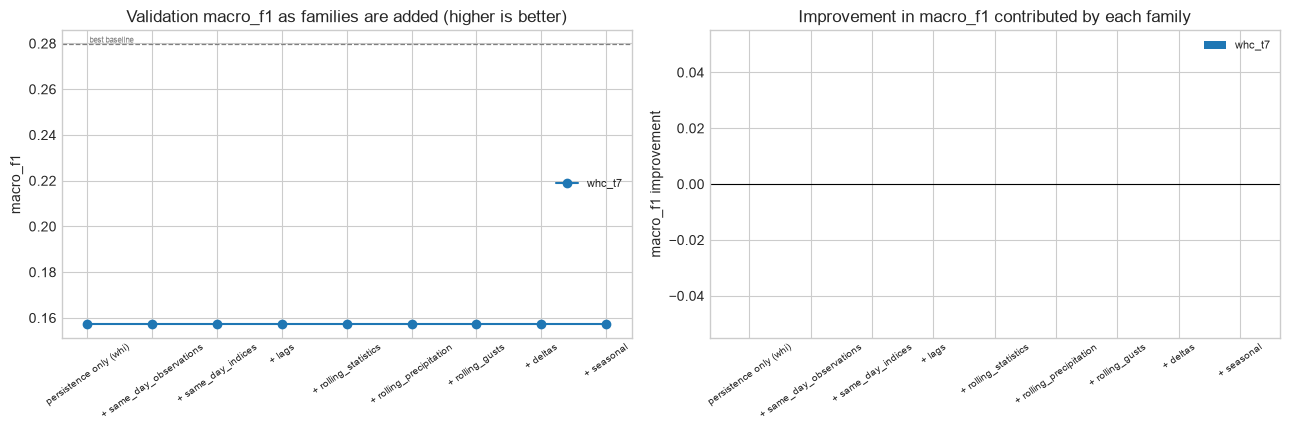

In [6]:
ABLATION_CONFIGS = xp.cumulative_feature_sets(task)


def ablation_score(columns: list[str], target: str) -> dict[str, float]:
    """Fit the default configuration on one feature subset and score it on validation."""
    _, predictions = fit_model(ABLATION_PARAMS, columns)
    return xp.classification_metrics(y["val"][target], predictions["val"], METRIC_LABELS)


ABLATION = xp.run_ablation(ABLATION_CONFIGS, ablation_score, [TARGET])
fig, ABLATION_F1 = xp.plot_ablation(
    task, ABLATION, "macro_f1", [TARGET], f"{EXPERIMENT}-ablation",
    higher_is_better=True, reference={"best baseline": BASELINE_F1},
)
summary = ABLATION.set_index("config")[["n_features", "macro_f1", "balanced_accuracy",
                                        "accuracy", "mean_ordinal_error"]]
print("Validation scores by cumulative feature set (macro F1: higher is better):\n")
print(summary.to_string())
plt.show()

## 5. Configuration: there is nothing to select

### Why there is no search of any kind in this notebook

The other four hazard notebooks use Optuna because their hyperparameter spaces are continuous,
interacting and far too large to enumerate. This notebook has no space at all. The null model is
fixed at `DummyClassifier(strategy="most_frequent")`: it predicts the majority training class for
every row, and that rule has no parameters.

Fixing it is a deliberate choice rather than a simplification. sklearn offers other strategies —
sampling from the training class distribution, or predicting classes uniformly — and picking the
best of them on validation macro F1 would raise the reported floor. But it would raise it by
*searching the validation split*, which makes the floor an artefact of that search rather than a
fixed property of the label distribution. A baseline that moves depending on how hard you looked
for it is not a baseline.

`most_frequent` is also the right rule specifically for this project, because it is the
degenerate model every other hazard notebook is at risk of becoming. A gradient-boosted ensemble
that collapses onto the majority class produces exactly these predictions at vastly greater cost.
Having its scores fixed and named makes that collapse immediately recognisable in the comparison
table.

### Which metric, and the argument this notebook settles

**Macro-averaged F1 on the validation split** — the same objective every other hazard notebook
maximises, so the floor is measured on the same scale as everything compared against it. Macro F1
is averaged over the classes present in the **training** split; the confusion matrix in section 6
still shows all four brief classes, so an absent class appears as an empty row rather than being
quietly dropped.

Nothing is being optimised here, but the metric choice still has to be justified, and this is the
notebook that justifies it by measurement. This model's accuracy will sit near the majority class
share while its macro F1 sits near the floor, because it scores a hard zero on every class it
never predicts. Those two numbers side by side are the evidence that selecting on accuracy would
rank a model with no operational value first — which is why no notebook in this project does so.

Section 6 evaluates this model exactly as every other notebook evaluates its tuned model. The
cells below only verify that the estimator is the rule it claims to be, and record the metric
comparison that argument rests on.

In [7]:
from sklearn.metrics import f1_score

BEST_PARAMS = dict(DEFAULT_PARAMS)
print(f"Fixed configuration: {BEST_PARAMS}")

# Verify the estimator is the rule it claims to be, rather than trusting the strategy name.
_, predictions = fit_model(BEST_PARAMS)
majority_class = int(y["train"][TARGET].mode().iloc[0])
predicted_classes = np.unique(predictions["val"])
if list(predicted_classes) != [majority_class]:
    raise AssertionError(
        f"Expected a constant prediction of class {majority_class}, "
        f"got {list(predicted_classes)}."
    )
print(f"Verified: predicts class {majority_class} "
      f"({task.class_labels[majority_class]}) for all {len(predictions['val'])} "
      "validation rows.")

# The argument that accuracy is the wrong selection metric for this target, measured.
METRIC_ARGUMENT = pd.DataFrame([{
    "model": "most_frequent (this notebook)",
    **xp.classification_metrics(y["val"][TARGET], predictions["val"], METRIC_LABELS),
}] + [
    {"model": label,
     **xp.classification_metrics(y["val"][TARGET], prediction, METRIC_LABELS)}
    for label, prediction in BASELINE_PREDICTIONS.items()
]).set_index("model")[["accuracy", "macro_f1", "balanced_accuracy", "mean_ordinal_error"]]

print("\nThe metric argument, measured rather than asserted:\n")
print(METRIC_ARGUMENT.to_string())
print("\nA rule with accuracy near the majority share and macro F1 near the floor is exactly")
print("what optimising accuracy would select. That is why every notebook in this project")
print("maximises macro F1 instead.")

Fixed configuration: {'strategy': 'most_frequent'}
Verified: predicts class 0 (Low Risk) for all 359 validation rows.

The metric argument, measured rather than asserted:

                               accuracy  macro_f1  balanced_accuracy  mean_ordinal_error
model                                                                                   
most_frequent (this notebook)     0.460     0.157              0.333               0.585
majority_class                    0.460     0.157              0.333               0.585
persistence                       0.429     0.224              0.298               0.621
seasonal_mode                     0.549     0.280              0.385               0.482

A rule with accuracy near the majority share and macro F1 near the floor is exactly
what optimising accuracy would select. That is why every notebook in this project
maximises macro F1 instead.


## 6. Final model and evaluation against the baselines

The selected hyperparameters are refitted and scored against all three baselines and against the
default configuration, so the notebook reports what tuning actually bought.

The confusion matrix is the most informative output in this notebook and belongs in the report.
It shows all four brief classes, including any that never occur, and it lets a reader apply their
own view of the relative cost of a missed hazard versus a false alarm — something no single
summary metric can express.

`mean_ordinal_error` exploits the fact that the classes are ordered. Predicting Low Risk when the
truth is Extreme is a worse failure than predicting Moderate, and a plain classification metric
cannot see that difference.

The class timeline plots the predicted and observed classes across 2024 with the underlying WHI
overlaid. Errors clustered near a class boundary are a different problem from errors made deep
inside a class: the first is a thresholding artefact of a continuous index being cut into bands,
the second is a genuine failure to read the weather.

Validation performance:

                 accuracy  balanced_accuracy  macro_f1  weighted_f1  macro_recall  macro_precision  mean_ordinal_error
model                                                                                                                 
dummy               0.460              0.333     0.157        0.289         0.250            0.115               0.585
dummy (default)     0.460              0.333     0.157        0.289         0.250            0.115               0.585
majority_class      0.460              0.333     0.157        0.289         0.250            0.115               0.585
persistence         0.429              0.298     0.224        0.428         0.224            0.224               0.621
seasonal_mode       0.549              0.385     0.280        0.533         0.289            0.278               0.482

Macro F1 gain over each reference (positive means the tuned model is better):

                 reference_macro_f1  macro_f1_gain
reference  

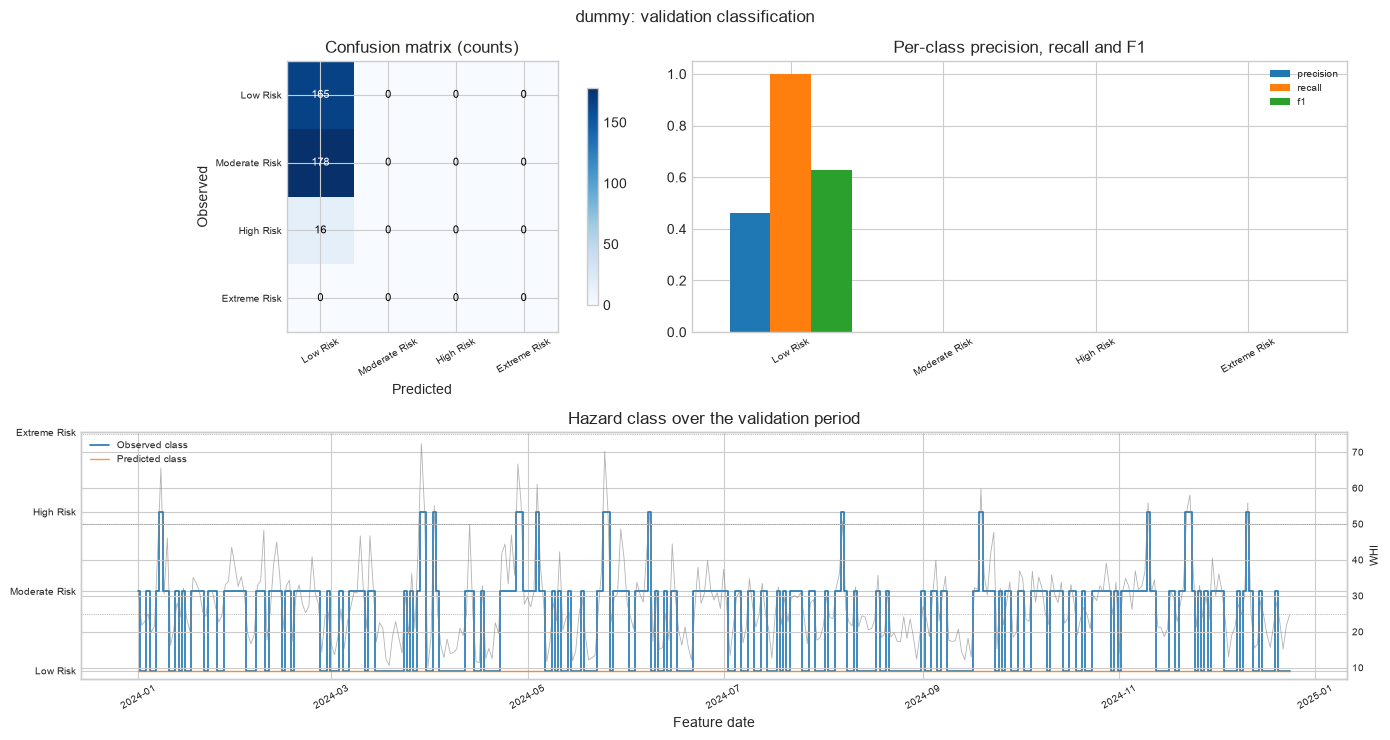


Misclassified days: 194 of 359
  median distance from the nearest class boundary: 5.9 WHI points
  share within 5 WHI points of a boundary: 39.2%


In [8]:
model, predictions = fit_model(BEST_PARAMS)
models = {TARGET: model}
VAL_PREDICTION = predictions["val"]
TRAIN_PREDICTION = predictions["train"]

rows = [
    {"model": MODEL_LABEL,
     **xp.classification_metrics(y["val"][TARGET], VAL_PREDICTION, METRIC_LABELS)},
    {"model": f"{MODEL_LABEL} (default)",
     **xp.classification_metrics(y["val"][TARGET], default_predictions["val"], METRIC_LABELS)},
]
for label, prediction in BASELINE_PREDICTIONS.items():
    rows.append({"model": label,
                 **xp.classification_metrics(y["val"][TARGET], prediction, METRIC_LABELS)})
RESULTS = pd.DataFrame(rows).set_index("model")
print("Validation performance:\n")
print(RESULTS.to_string())

tuned_f1 = RESULTS.loc[MODEL_LABEL, "macro_f1"]
comparison = pd.DataFrame([{
    "reference": reference,
    "reference_macro_f1": RESULTS.loc[reference, "macro_f1"],
    "macro_f1_gain": tuned_f1 - RESULTS.loc[reference, "macro_f1"],
} for reference in RESULTS.index if reference != MODEL_LABEL]).set_index("reference")
print("\nMacro F1 gain over each reference (positive means the tuned model is better):\n")
print(comparison.to_string())

AUX = task.load_aux("val")
fig, PER_CLASS = xp.plot_classification_validation(
    task, X["val"].index, y["val"][TARGET], VAL_PREDICTION, REPORT_LABELS,
    MODEL_LABEL, f"{EXPERIMENT}-validation", whi=AUX[task.auxiliary_columns[0]],
)
print("\nPer-class validation performance (all four brief classes shown):\n")
print(PER_CLASS.to_string())
plt.show()

# Errors near a class boundary are a thresholding artefact; errors deep inside a class are not.
errors = VAL_PREDICTION != y["val"][TARGET].to_numpy()
if errors.any():
    distance = AUX[task.auxiliary_columns[0]].to_numpy()[errors]
    boundary_distance = np.min(np.abs(distance[:, None] - np.array([25, 50, 75])), axis=1)
    print(f"\nMisclassified days: {int(errors.sum())} of {len(errors)}")
    print(f"  median distance from the nearest class boundary: "
          f"{np.median(boundary_distance):.1f} WHI points")
    print(f"  share within 5 WHI points of a boundary: "
          f"{float(np.mean(boundary_distance < 5)):.1%}")

## 7. Feature attribution

There is nothing to attribute. This estimator makes no use of the feature matrix, which is the
entire point of a null model: it establishes what can be achieved from the label distribution
alone, so that every other notebook's performance can be read as the value added by the features.

The feature column list is still recorded in the exported bundle, so that the comparison notebook
and the `/model-metadata` endpoint can treat every experiment's artefacts identically.

In [9]:
# A dummy estimator ignores the feature matrix entirely, so there is no importance to report.
# The empty frame keeps the artefact schema identical to the other experiments, which is what
# lets the comparison notebook and the /model-metadata endpoint treat every bundle the same way.
IMPORTANCES = pd.DataFrame()
print("No feature importance: this estimator makes no use of the feature matrix.")
print(f"Feature columns are still recorded ({len(task.feature_columns)}) so that every "
      "experiment\nbundle carries the same contract.")

No feature importance: this estimator makes no use of the feature matrix.
Feature columns are still recorded (105) so that every experiment
bundle carries the same contract.


## 8. Generalisation check

Training and validation performance side by side. For an imbalanced classification task the
informative comparison is macro F1, not accuracy: accuracy will look similar on both splits
simply because the majority class dominates each of them.

Read this together with the seed-stability table in section 5. A model with a wide train-to-
validation macro F1 gap *and* a large seed spread is fitting noise, which on a target with this
few minority-class examples is the expected failure mode rather than a surprising one.

In [10]:
gap_rows = []
for split, prediction in (("train", TRAIN_PREDICTION), ("val", VAL_PREDICTION)):
    gap_rows.append({"split": split,
                     **xp.classification_metrics(y[split][TARGET], prediction, METRIC_LABELS)})
GAP = pd.DataFrame(gap_rows).set_index("split")
print(GAP.to_string())

print("\nTrain-to-validation change:")
for metric in ("macro_f1", "balanced_accuracy", "accuracy"):
    print(f"  {metric:<18} {GAP.loc['train', metric]:.4f} -> {GAP.loc['val', metric]:.4f} "
          f"({GAP.loc['val', metric] - GAP.loc['train', metric]:+.4f})")

print("\nPredicted class distribution by split:")
print(pd.DataFrame({
    "train": pd.Series(TRAIN_PREDICTION).value_counts(),
    "val": pd.Series(VAL_PREDICTION).value_counts(),
}).reindex(REPORT_LABELS).fillna(0).astype(int)
  .rename(index=task.class_labels).to_string())

       accuracy  balanced_accuracy  macro_f1  weighted_f1  macro_recall  macro_precision  mean_ordinal_error
split                                                                                                       
train     0.503              0.250     0.167        0.336         0.250            0.126               0.541
val       0.460              0.333     0.157        0.289         0.250            0.115               0.585

Train-to-validation change:
  macro_f1           0.1672 -> 0.1574 (-0.0098)
  balanced_accuracy  0.2500 -> 0.3333 (+0.0833)
  accuracy           0.5026 -> 0.4596 (-0.0430)

Predicted class distribution by split:
               train  val
Low Risk        2885  359
Moderate Risk      0    0
High Risk          0    0
Extreme Risk       0    0


## 9. Saved artefacts

The fitted classifier is written together with a metadata document shaped for the
`/model-metadata` endpoint: target, algorithm, forecast horizon, feature list, feature importance,
selected hyperparameters, class labels and validation metrics.

The metadata records the exact feature column order. The API must construct its feature vector in
that order, since the estimator receives an unnamed array at prediction time and will silently
produce wrong answers if the columns are permuted. It also records the class-code mapping, which
the endpoint needs in order to return `"Moderate Risk"` rather than `1`.

The test split remains unused.

In [11]:
model_entries = [{
    "target": task.target_name,
    "target_column": TARGET,
    "prediction_type": "multiclass_classification",
    "algorithm": ALGORITHM_NAME,
    "forecast_horizon": f"{task.horizons[0]} Days",
    "hyperparameters": {k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v))
                        for k, v in BEST_PARAMS.items()},
    "features": task.feature_columns,
    "feature_importance": {
        column: float(value) for column, value
        in IMPORTANCES[TARGET].sort_values(ascending=False).head(20).items()
    } if not IMPORTANCES.empty else {},
    "classes_trained": [int(c) for c in LABELS.classes_],
    "class_names": {str(c): task.class_labels[c] for c in LABELS.classes_},
    "validation_metrics": RESULTS.loc[MODEL_LABEL].to_dict(),
    "per_class_validation": PER_CLASS.reset_index().to_dict(orient="records"),
    "baseline_metrics": {reference: RESULTS.loc[reference].to_dict()
                         for reference in BASELINE_PREDICTIONS},
}]

METADATA = xp.build_metadata(
    task, EXPERIMENT, ALGORITHM_NAME, model_entries,
    best_params={k: str(v) for k, v in BEST_PARAMS.items()},
    extra={
        "optimisation": {
            "library": None,
            "method": "none - fixed majority-class rule",
            "strategy": BEST_PARAMS["strategy"],
            "objective": "validation macro-averaged F1 over classes seen in training",
            "classes_averaged": [int(c) for c in METRIC_LABELS],
            "note": (
                "A majority-class null model has nothing to tune. It is fixed rather than "
                "selected so that the floor it establishes is a fixed property of the label "
                "distribution, not an artefact of searching the validation split."
            ),
        },
        "class_imbalance_note": (
            "Accuracy is not a meaningful selection metric for this target; macro F1 and the "
            "confusion matrix are the reportable results."
        ),
    },
)
bundle = xp.export_experiment(task, EXPERIMENT, models, METADATA, MODEL_FAMILY)
print(f"Saved bundle: {bundle.relative_to(PROJECT_ROOT)}")
print("\nThe test split has still not been touched. It should be used exactly once, after a")
print("single model has been selected on validation performance across all experiments.")

Saved bundle: models/weather_hazard/experiments/whc_dummy

The test split has still not been touched. It should be used exactly once, after a
single model has been selected on validation performance across all experiments.


## 10. Conclusions

- **This is the floor, not the bar.** Persistence and the seasonal mode both use information and
  should beat it. Report how far they sit above this model: that gap measures what today's
  weather and the calendar are each worth before any model is fitted.
- **The metric argument, settled empirically.** Put this model's accuracy and macro F1 side by
  side in the report. One number near the majority share and one near the floor is the clearest
  possible justification for not optimising accuracy on this target.
- **The collapse test.** Any hazard model whose confusion matrix resembles this one has collapsed
  onto the majority class, whatever its headline macro F1. Check the other four notebooks'
  matrices against this one before reporting any of them as successful.
- **Not a deployment candidate.** This notebook exists to calibrate the others.

The test split has still not been touched. It should be used exactly once, after a single model
has been selected on validation performance across all ten experiment notebooks.